In [39]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import MaxNLocator

from src.environment import ShuttleEnvironment, ShuttleEnvironmentAction

# Single-hue sequential ramp (light -> dark) for probabilities
PROBABILITY_CMAP = LinearSegmentedColormap.from_list(
    "blues", ["#b7d3f6", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
PROBABILITY_CMAP.set_bad("white")  # Unreachable states
BAR_COLOR = "#2a78d6"
INK = "#0b0b0b"
MUTED_INK = "#52514e"

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED_INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "xtick.color": MUTED_INK,
        "ytick.color": MUTED_INK,
    }
)

In [50]:
def simulate(action: ShuttleEnvironmentAction, arriving_probabilities: list[float]):
    env = ShuttleEnvironment(
        shuttle_capacity=15,
        shuttle_dispatch_cost=100,
        customer_waiting_cost=2,
        customer_arriving_options=[1, 2, 3, 4, 5],
        customer_arriving_probabilities=arriving_probabilities,
    )

    T = 20
    max_state = T * max(env.customer_arriving_options)

    # probabilities[t, s] = P(S_t = s)
    probabilities = np.zeros((T + 1, max_state + 1))
    probabilities[0, 0] = 1.0

    for t in range(T):
        for state in np.flatnonzero(probabilities[t]):
            current_prob = probabilities[t, state]

            for p, next_state, _ in env.transitions(int(state), action):
                probabilities[t + 1, next_state] += current_prob * p

    unreachable = probabilities == 0
    expected_state = probabilities @ np.arange(max_state + 1)

    # Only show states up to the largest reachable one (plus a small margin)
    max_reachable = np.flatnonzero(~unreachable.all(axis=0)).max()
    max_shown = max(max_reachable + 3, env.shuttle_capacity + 3)

    fig, (ax_dist, ax_heatmap) = plt.subplots(
        1, 2, figsize=(15, 6), width_ratios=(1, 3)
    )

    # Left: arrival probability distribution
    bars = ax_dist.bar(
        env.customer_arriving_options,
        arriving_probabilities,
        width=0.6,
        color=BAR_COLOR,
    )
    ax_dist.bar_label(
        bars,
        labels=[f"{p:.2f}" if p > 0 else "" for p in arriving_probabilities],
        padding=3,
        color=INK,
    )
    ax_dist.set(
        title="Arrivals per Period",
        xlabel="Customers arriving",
        ylabel="Probability",
        xticks=env.customer_arriving_options,
        ylim=(0, 1.1),
    )
    ax_dist.grid(axis="y", color="#e6e5e0")
    ax_dist.set_axisbelow(True)

    # Right: state distribution over time, unreachable states masked out
    im = ax_heatmap.imshow(
        np.ma.masked_where(unreachable, probabilities)[:, : max_shown + 1].T,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=PROBABILITY_CMAP,
        norm=LogNorm(
            vmin=1e-4, vmax=1, clip=True
        ),  # Log scale so small probabilities stay visible
        extent=(-0.5, T + 0.5, -0.5, max_shown + 0.5),
    )
    ax_heatmap.set(
        title="State Distribution Over Time",
        xlabel="Time step $t$",
        ylabel="State $s$ (waiting customers)",
        xticks=range(0, T + 1, 2),
    )
    ax_heatmap.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax_heatmap.legend(loc="upper left", framealpha=0.9)

    cbar = fig.colorbar(im, ax=ax_heatmap, pad=0.02)
    cbar.set_label(r"$P(S_t = s)$, log scale  (white = unreachable)")
    cbar.outline.set_visible(False)

    fig.suptitle(
        f"Always {action.name}, arrival probabilities "
        f"{[round(p, 2) for p in arriving_probabilities]}",
        fontsize=15,
        fontweight="bold",
    )
    fig.tight_layout()
    plt.show()

C:\Users\Johannes\AppData\Local\Temp\ipykernel_40864\3898533550.py:77: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_heatmap.legend(loc="upper left", framealpha=0.9)


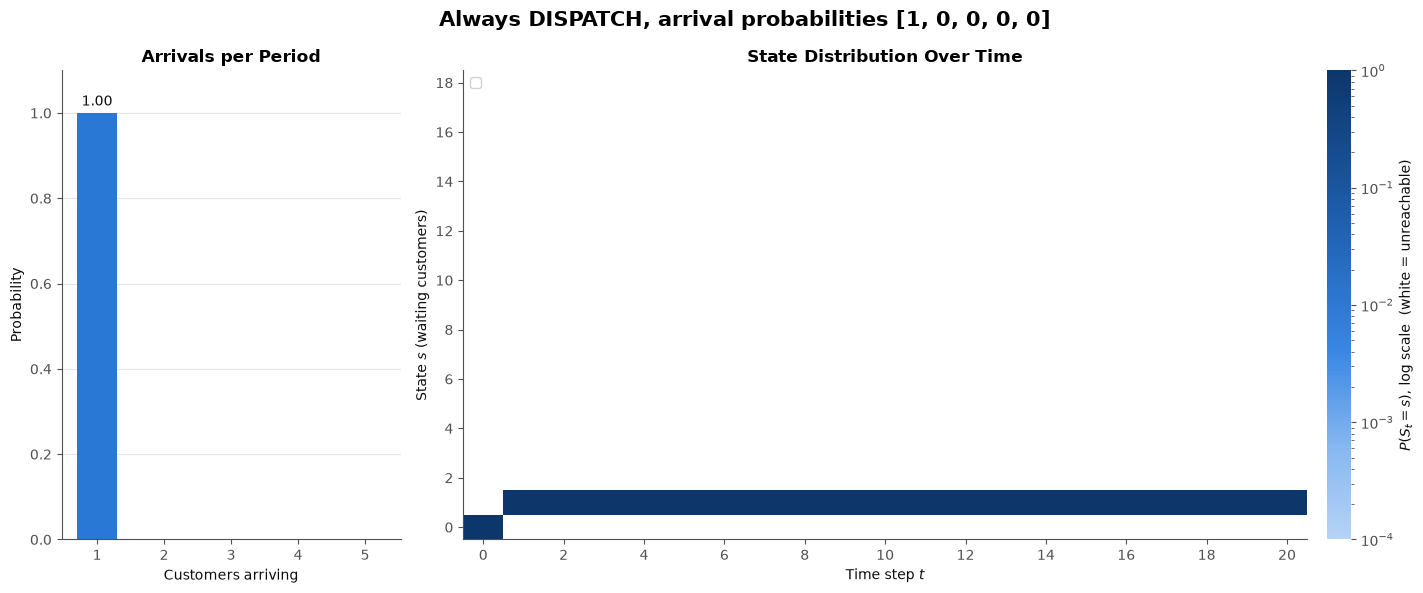

In [51]:
simulate(ShuttleEnvironmentAction.DISPATCH, [1, 0, 0, 0, 0])

C:\Users\Johannes\AppData\Local\Temp\ipykernel_40864\3898533550.py:77: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_heatmap.legend(loc="upper left", framealpha=0.9)


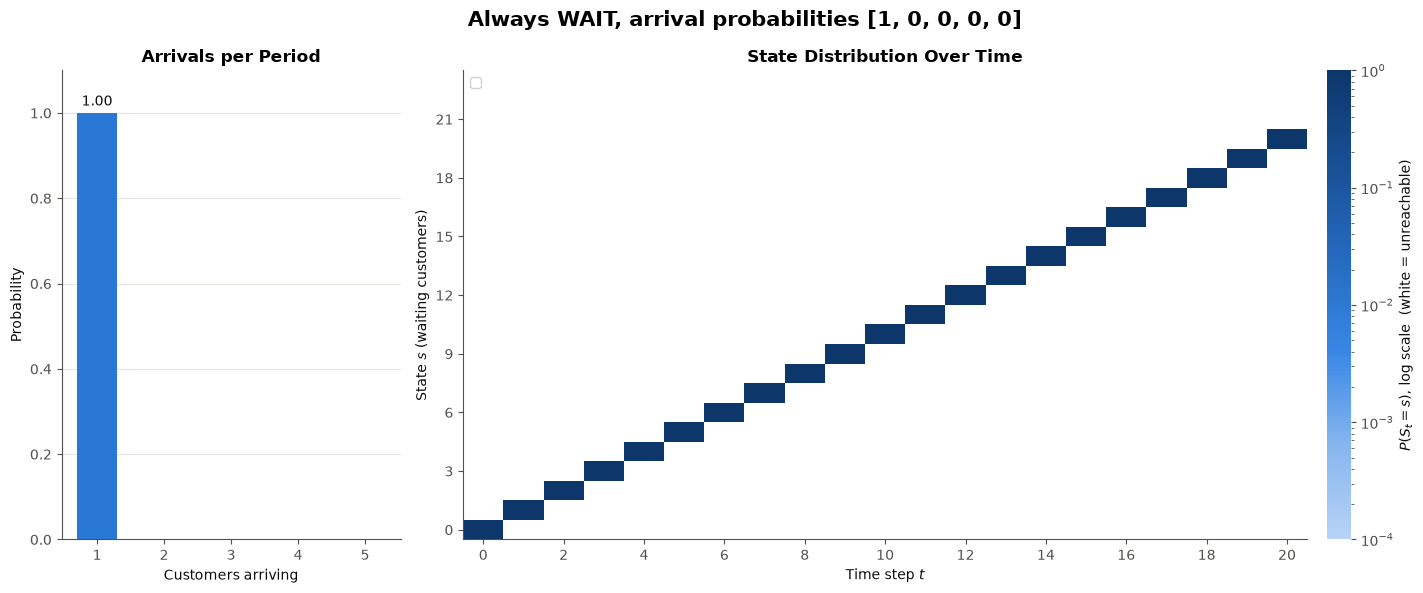

In [52]:
simulate(ShuttleEnvironmentAction.WAIT, [1, 0, 0, 0, 0])

C:\Users\Johannes\AppData\Local\Temp\ipykernel_40864\3898533550.py:77: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_heatmap.legend(loc="upper left", framealpha=0.9)


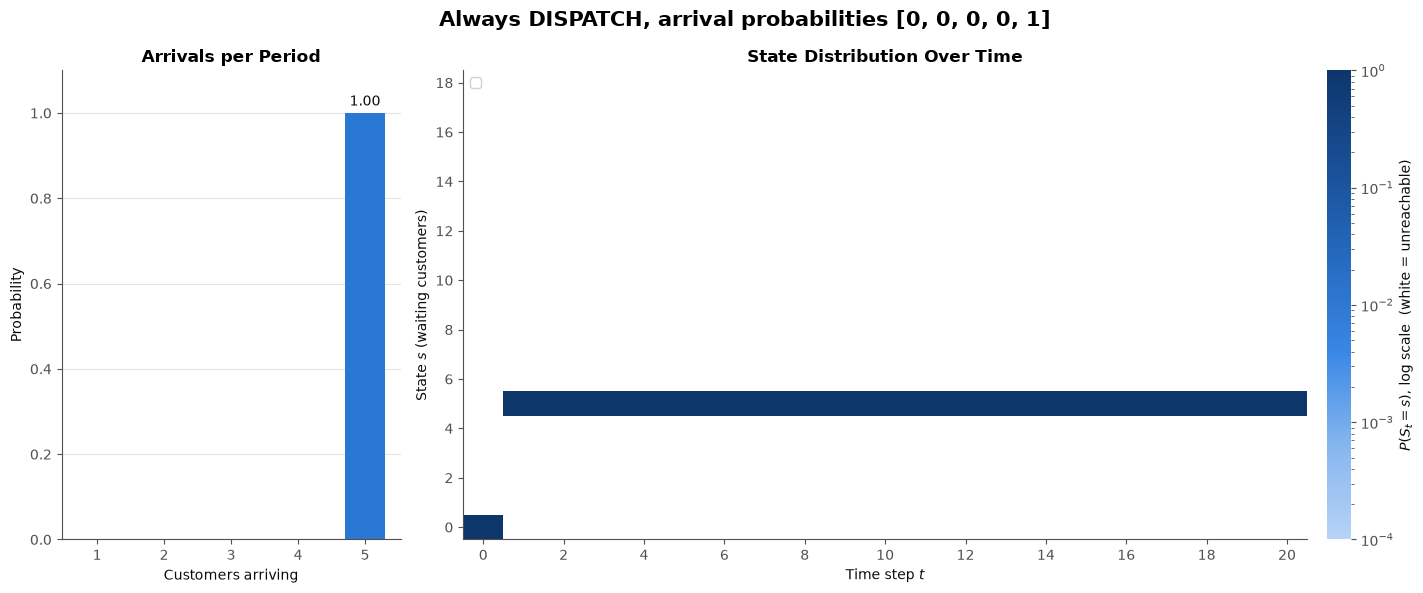

In [53]:
simulate(ShuttleEnvironmentAction.DISPATCH, [0, 0, 0, 0, 1])

C:\Users\Johannes\AppData\Local\Temp\ipykernel_40864\3898533550.py:77: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_heatmap.legend(loc="upper left", framealpha=0.9)


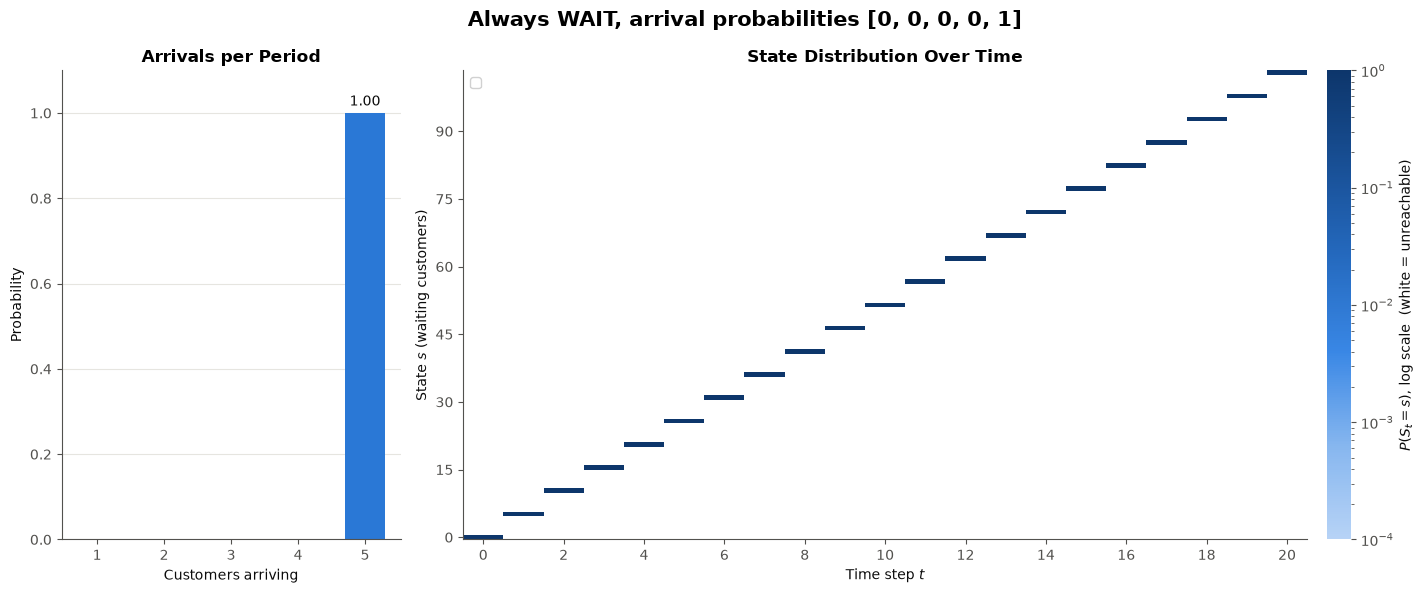

In [54]:
simulate(ShuttleEnvironmentAction.WAIT, [0, 0, 0, 0, 1])

C:\Users\Johannes\AppData\Local\Temp\ipykernel_40864\3898533550.py:77: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_heatmap.legend(loc="upper left", framealpha=0.9)


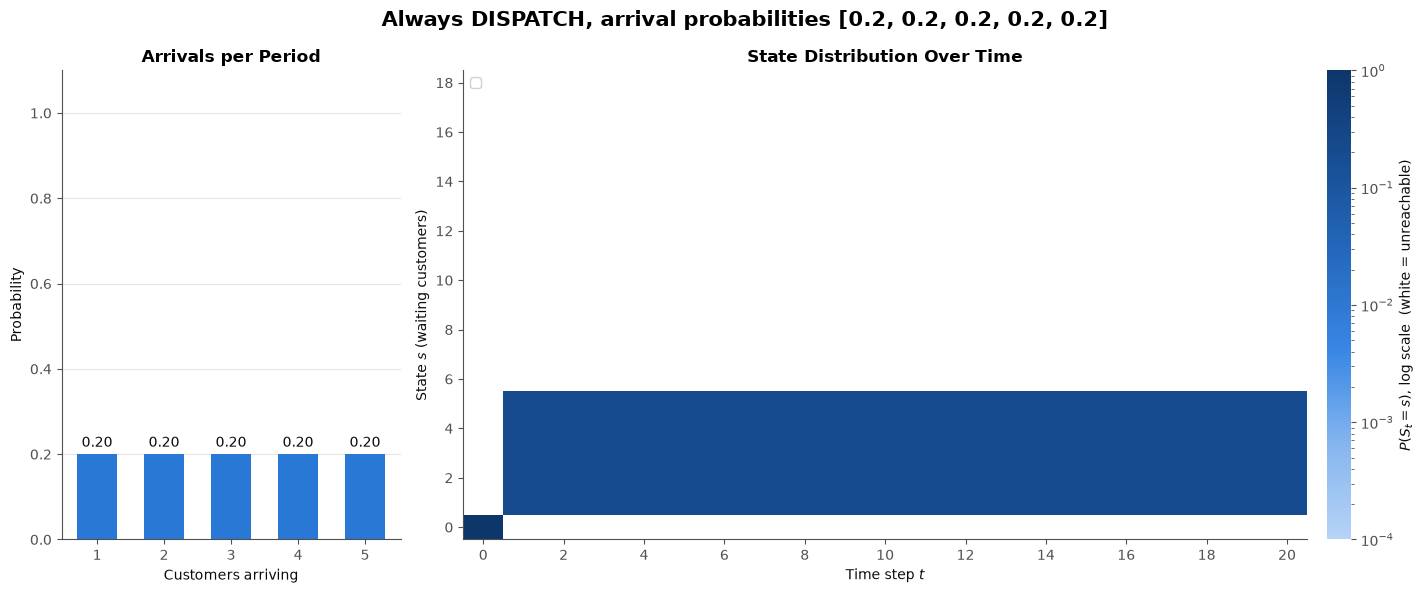

In [55]:
simulate(ShuttleEnvironmentAction.DISPATCH, [0.2, 0.2, 0.2, 0.2, 0.2])

C:\Users\Johannes\AppData\Local\Temp\ipykernel_40864\3898533550.py:77: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_heatmap.legend(loc="upper left", framealpha=0.9)


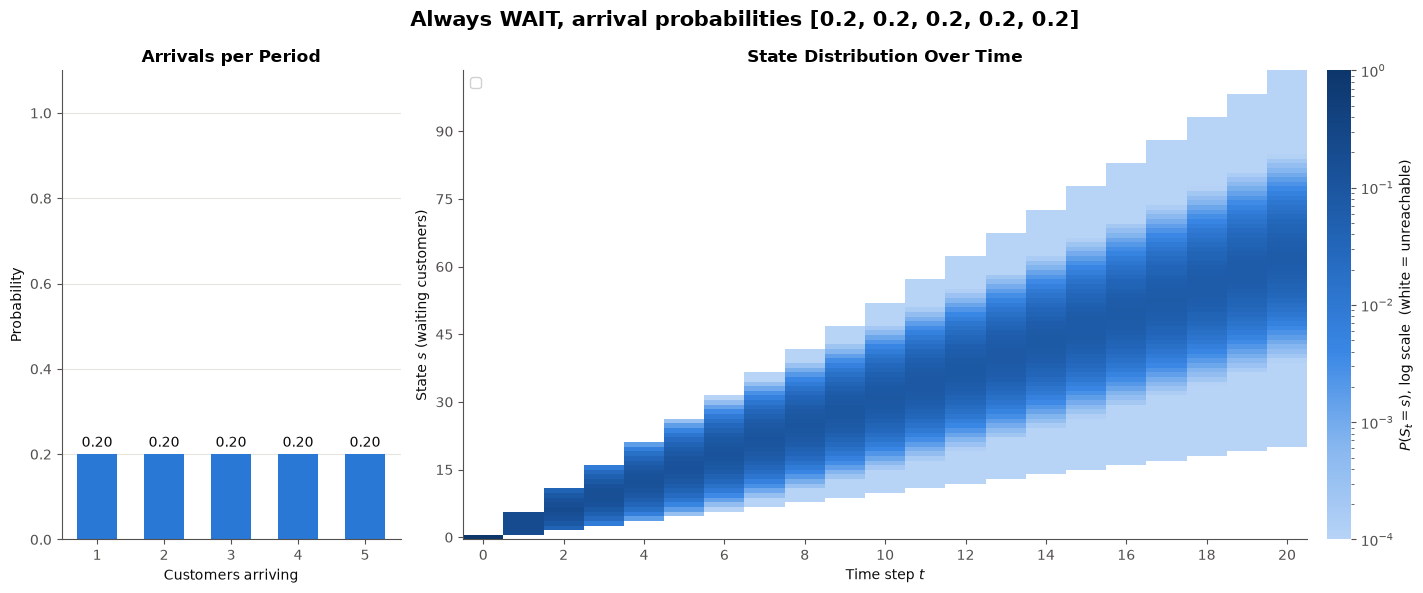

In [56]:
simulate(ShuttleEnvironmentAction.WAIT, [0.2, 0.2, 0.2, 0.2, 0.2])